# Examen Práctico — Primer Parcial
## Tópicos de Big Data

**Instrucciones generales**

- Este notebook es tu entregable. Complétalo en orden, sin borrar los enunciados.
- Al final debes subir este archivo (`.ipynb`) al repositorio de GitHub del curso, en la carpeta correspondiente a tu nombre/usuario.
- Se evaluará tanto el código (que corra sin errores, de arriba hacia abajo) como tus interpretaciones escritas en las celdas de texto marcadas como *"Interpretación"*.
- Cada quien trabaja con **un dataset distinto**, asignado por la profesora. No copies celdas de un compañero con un dataset diferente: aunque las preguntas se parecen, los datos y las columnas no son las mismas.


## 0. Datos del alumno

Completa la siguiente celda con tus datos y el nombre del dataset que te fue asignado.

In [198]:
# --- COMPLETA CON TUS DATOS ---
NOMBRE = "Santiago Martínez"            # Tu nombre completo
MATRICULA = "81194"         # Tu matrícula o número de cuenta
DATASET_ASIGNADO = "homicidios"  # Debe ser uno de: "alcohol", "migracion", "desnutricion", "pib", "homicidios"

print(f"Alumno: {NOMBRE}")
print(f"Matrícula: {MATRICULA}")
print(f"Dataset asignado: {DATASET_ASIGNADO}")


Alumno: Santiago Martínez
Matrícula: 81194
Dataset asignado: homicidios


## 1. Configuración del entorno virtual (Visual Studio Code)

Antes de instalar librerías directamente en tu sistema, es una buena práctica crear un
**entorno virtual** exclusivo para este examen. Esto evita conflictos de versiones con
otros proyectos y hace que tu entorno de trabajo sea reproducible.

**Requisitos previos en VS Code:** ten instaladas las extensiones oficiales **"Python"**
y **"Jupyter"** (ambas de Microsoft), disponibles en la pestaña de Extensiones (ícono de
cuadritos en la barra lateral izquierda, o `Ctrl+Shift+X` / `Cmd+Shift+X`).

Abre una terminal **dentro de VS Code** (menú **Terminal → New Terminal**, o
`` Ctrl+ñ ``/`` Ctrl+` ``) y verifica que estés ubicado en la carpeta de tu repositorio
del curso (donde vas a guardar este notebook).

### Windows (PowerShell, terminal integrada de VS Code)

```powershell
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python -m venv .venv

# 2. Activar el entorno virtual
.venv\Scripts\Activate.ps1

# Si PowerShell bloquea la ejecución de scripts, ejecuta una sola vez:
#   Set-ExecutionPolicy -Scope CurrentUser RemoteSigned
# y vuelve a intentar activar el entorno.

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

### macOS / Linux (terminal integrada de VS Code, bash o zsh)

```bash
# 1. Crear el entorno virtual (se creará una carpeta llamada ".venv")
python3 -m venv .venv

# 2. Activar el entorno virtual
source .venv/bin/activate

# 3. Instalar las librerías necesarias
pip install pandas numpy ipykernel matplotlib requests
```

> **Nota:** usamos el nombre `.venv` (con punto) porque VS Code lo detecta automáticamente
> dentro de la carpeta del proyecto. Si usas Anaconda/Miniconda en lugar de `venv`, el
> equivalente es:
> ```bash
> conda create -n examen-bigdata python=3.11 pandas numpy ipykernel matplotlib requests -y
> conda activate examen-bigdata
> ```

### Seleccionar el entorno virtual como kernel en VS Code

A diferencia de Jupyter Notebook/Lab, en VS Code **no necesitas registrar el entorno
manualmente con `ipykernel install`**: basta con tener el paquete `ipykernel` instalado
en el entorno (ya quedó instalado en el paso anterior) y seleccionar ese entorno
directamente como kernel del notebook.

1. Abre este archivo `.ipynb` en VS Code.
2. En la esquina superior derecha del notebook, haz clic en el selector de kernel
   (dice algo como **"Select Kernel"** la primera vez).
3. Elige **"Python Environments..."** y de la lista selecciona el entorno `.venv`
   que acabas de crear (debe aparecer como algo como `.venv (Python 3.x.x)` con la
   ruta de tu proyecto).
4. Si no aparece en la lista, haz clic en **"Select Another Kernel" → "Python
   Environments..."** y usa **"Enter interpreter path..."** para localizar manualmente
   el ejecutable dentro de `.venv/bin/python` (macOS/Linux) o `.venv\Scripts\python.exe`
   (Windows).
5. Verifica que quedó bien seleccionado ejecutando la celda de abajo: debe mostrar una
   ruta que contenga la carpeta `.venv` (o el nombre de tu entorno de conda), y no la
   instalación global de Python.

In [199]:
import sys
print(sys.executable)
# Debe mostrar una ruta dentro de tu carpeta "venv" (o de tu entorno "examen-bigdata" si usas conda).
# Si muestra la ruta de tu instalacion global de Python, regresa al paso anterior
# y selecciona el kernel correcto antes de continuar.


c:\Users\Santiago\Desktop\Escuela\5to Semestre ISSC\BigData\U1_1\.venv\Scripts\python.exe


## 2. Configuración y carga de datos

La siguiente celda **no se modifica**. Contiene la configuración de los 5 datasets
posibles del examen. A partir de tu variable `DATASET_ASIGNADO` de la celda anterior,
el notebook cargará automáticamente el dataset y los metadatos que te corresponden.

In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# --- NO MODIFICAR: configuración de los 5 datasets del examen ---
DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",       # columna a usar para filtrar países reales vs. agregados
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS, (
    "DATASET_ASIGNADO debe ser uno de: " + ", ".join(DATASETS.keys())
)

config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: homicidios
Descripcion: Numero de homicidios intencionales por anio (homicidios)


In [201]:
# Carga de datos y metadatos desde Our World in Data
df = pd.read_csv(
    config["csv"],
    storage_options={'User-Agent': 'Our World In Data data fetch/1.0'}
)
metadata = requests.get(config["meta"]).json()

# Renombramos la columna de valor a "valor" para trabajar mas comodo durante todo el notebook
df = df.rename(columns={config["valor_col"]: "valor"})


In [202]:
df.head(25)

,entity,code,year,valor,owid_region
0,Afghanistan,AFG,2009,1115.000,Asia
1,Afghanistan,AFG,2010,983.000,Asia
2,Afghanistan,AFG,2011,1231.000,Asia
3,Afghanistan,AFG,2012,1948.000,Asia
4,Afghanistan,AFG,2015,3367.000,Asia
5,Afghanistan,AFG,2016,2318.000,Asia
6,Afghanistan,AFG,2017,2424.000,Asia
7,Afghanistan,AFG,2018,2474.000,Asia
8,Afghanistan,AFG,2019,2712.000,Asia
9,Afghanistan,AFG,2020,2570.000,Asia


## 3. Exploración inicial

Antes de responder las preguntas de análisis, explora el dataset: tipos de datos,
dimensiones, valores nulos y estadísticas descriptivas básicas.

In [203]:
# Forma del dataset (filas, columnas)
df.shape


(4914, 5)

In [204]:
# Tipos de datos e informacion general
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4914 entries, 0 to 4913
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   entity       4914 non-null   str    
 1   code         4399 non-null   str    
 2   year         4914 non-null   int64  
 3   valor        4914 non-null   float64
 4   owid_region  4220 non-null   str    
dtypes: float64(1), int64(1), str(3)
memory usage: 192.1 KB


In [205]:
# Estadisticas descriptivas de la columna 'valor'
df['valor'].describe()


count      4914.000000
mean       8582.853861
std       37590.820449
min           0.000000
25%          37.000000
50%         256.500000
75%        1171.968475
max      450728.880000
Name: valor, dtype: float64

In [206]:
# Conteo de valores nulos por columna
df.isnull().sum()


entity           0
code           515
year             0
valor            0
owid_region    694
dtype: int64

**Interpretación (2-3 líneas):** ¿qué observas sobre los valores nulos, el rango de
años y el tipo de variable con la que vas a trabajar?

Sobre los valores nulos de región pues son países que no están dados de alta en OWID o su región no está registrada oficialmente, donde se analizarán y comparará la tasa de homicidios anual de distintos países

## 4. Preguntas de análisis

A continuación responde las 10 preguntas. 

Cada una tiene una celda de código para su solución y, cuando aplica, 
una celda de texto para tu interpretación. Recuerda que tu
dataset (`DATASET_ASIGNADO`) puede o no tener la columna `owid_region`; revisa el
diccionario `DATASETS` de la celda de configuración para saber qué columna (`code` u
`owid_region`) te toca usar para distinguir países reales de agregados (continentes,
"World", grupos de ingreso, etc.).

### Pregunta 1 — Filtrado de países reales y ranking

Filtra el DataFrame para quedarte solo con países reales (usa la columna indicada en `config['filtro_paises']` de tu dataset). Guarda el resultado en una nueva variable `df_paises`. ¿Cuántos países distintos hay? Muestra los 10 países con mayor valor y los 10 con menor valor.

In [207]:
# Pregunta 1
# Tu codigo aqui

df_paises = df[df[config["filtro_paises"]].notnull()]

print("Top 10 países con mayor valor:")
display(df_paises.nlargest(10, 'valor'))


print("Top 10 países con menor valor:")
display(df_paises.nsmallest(10, 'valor'))

Top 10 países con mayor valor:


,entity,code,year,valor,owid_region
716,Brazil,BRA,2017,63788.0,South America
3093,Nigeria,NGA,2016,63400.0,Africa
715,Brazil,BRA,2016,61208.0,South America
713,Brazil,BRA,2014,59733.0,South America
714,Brazil,BRA,2015,58184.0,South America
712,Brazil,BRA,2013,56845.0,South America
711,Brazil,BRA,2012,56388.0,South America
717,Brazil,BRA,2018,55980.0,South America
709,Brazil,BRA,2010,52289.0,South America
710,Brazil,BRA,2011,52233.0,South America


Top 10 países con menor valor:


,entity,code,year,valor,owid_region
102,American Samoa,ASM,2016,0.0,Oceania
105,American Samoa,ASM,2019,0.0,Oceania
132,Andorra,AND,2007,0.0,Europe
134,Andorra,AND,2009,0.0,Europe
135,Andorra,AND,2010,0.0,Europe
137,Andorra,AND,2012,0.0,Europe
138,Andorra,AND,2013,0.0,Europe
139,Andorra,AND,2014,0.0,Europe
140,Andorra,AND,2015,0.0,Europe
146,Anguilla,AIA,1990,0.0,North America


**Interpretación:**

Basados en los datos, los países más inseguros tienden a estar en Sudamérica y África mientras que los más seguros son en Europa siendo Andorra el país que historicamente ha sido el más seguro por muchos años al menos entre 2007 y 2015 con su contraparte donde Brazil se presenta como el país con mayor tasa de homicidios 

### Pregunta 2 — Filtro por país y rango de años

Elige dos paises (Mexico y algún otro de tu interés) y filtra `df_paises` para mostrar únicamente su información dentro del rango de años disponible para ambos.

In [208]:
# Pregunta 2
# Tu codigo aqui

mexico = df[df['entity'] == 'Mexico']
japan = df[df['entity'] == 'Japan']

display(mexico.shape)
display(japan.shape)

display(mexico.head(34))
display(japan.head(34))


(34, 5)

(34, 5)

,entity,code,year,valor,owid_region
2718,Mexico,MEX,1990,14493.0,North America
2719,Mexico,MEX,1991,15128.0,North America
2720,Mexico,MEX,1992,16594.0,North America
2721,Mexico,MEX,1993,16040.0,North America
2722,Mexico,MEX,1994,15839.0,North America
2723,Mexico,MEX,1995,15612.0,North America
2724,Mexico,MEX,1996,14505.0,North America
2725,Mexico,MEX,1997,13552.0,North America
2726,Mexico,MEX,1998,13656.0,North America
2727,Mexico,MEX,1999,12249.0,North America


,entity,code,year,valor,owid_region
2216,Japan,JPN,1990,676.0,Asia
2217,Japan,JPN,1991,639.0,Asia
2218,Japan,JPN,1992,673.0,Asia
2219,Japan,JPN,1993,715.0,Asia
2220,Japan,JPN,1994,751.0,Asia
2221,Japan,JPN,1995,724.0,Asia
2222,Japan,JPN,1996,652.0,Asia
2223,Japan,JPN,1997,710.0,Asia
2224,Japan,JPN,1998,775.0,Asia
2225,Japan,JPN,1999,736.0,Asia


**Interpretación:**

La diferencia de cantidad de homicidios entre México y Japón es abismal, historicamente México presenta dato mucho más altos que Japón, donde en nungún año no se podía comparar la cantidad de homicidios, aunque también un factor es la cantidad de población de ambos países

### Pregunta 3 — Comparación entre países

Elige 5 países de tu interés (de distintos continentes) y compara el valor de tu indicador en el año más reciente disponible. ¿Cuál tiene el valor más alto y cuál el más bajo? Calcula la diferencia entre ambos.

In [209]:
# Pregunta 3
# Tu codigo aqui
import pandas as pd

brazil = df[df['entity'] == 'Brazil']
nigeria = df[df['entity'] == 'Nigeria']
norway = df[df['entity'] == 'Norway']

lista_paises = [brazil, nigeria, norway, mexico, japan]
df_5_paises = pd.concat(lista_paises)

reciente = df_5_paises['year'].max()

df_reciente = df_5_paises[df_5_paises['year'] == reciente]
display(df_reciente)



,entity,code,year,valor,owid_region
722,Brazil,BRA,2023,40698.0,South America
3095,Nigeria,NGA,2023,35884.0,Africa
3260,Norway,NOR,2023,40.0,Europe
2751,Mexico,MEX,2023,32252.0,North America
2249,Japan,JPN,2023,285.0,Asia


**Interpretación:**

La diferencia entre los valores de países de América y Europa y Asia es abismal, lo que estadísticamente nos dice que hasta 2023, era más peligroso vivir en América que en Europa

### Pregunta 4 — Comparación entre grupos

Define dos grupos de países, el primero "latinoamerica" con Mexico, Colombia y Argentina, y el segundo "Asia" con China, Japon y Vietnam ( si algun pais no tiene informacion disponible, sustitúyelo por algún otro) y calcula el promedio de tu indicador en el año más reciente disponible.

In [210]:
# Pregunta 4
# Tu codigo aqui
latinoamerica = ['Mexico', 'Colombia', 'Argentina']
asia = ['China', 'Japan', 'Vietnam']

df_latam = df[df['entity'].isin(latinoamerica)]
df_asia = df[df['entity'].isin(asia)]

reciente_latam = df_latam['year'].max()
reciente_asia = df_asia['year'].max()

df_latam_reciente = df_latam[df_latam['year'] == reciente_latam]
df_asia_reciente = df_asia[df_asia['year'] == reciente_asia]

promedio_latam = df_latam_reciente['valor'].mean()
promedio_asia = df_asia_reciente['valor'].mean()

print(f"Promedio de valor en Latinoamérica (año {reciente_latam}): {promedio_latam}")
print(f"Promedio de valor en Asia (año {reciente_asia}): {promedio_asia}")


Promedio de valor en Latinoamérica (año 2023): 15777.666666666666
Promedio de valor en Asia (año 2023): 285.0


**Interpretación:**

En 2023 la tasa de homicidios en Latinoamérica era alrededor de 5 veces más grande que la de asia

### Pregunta 5 — Tendencia temporal de un país

Para un país de tu elección, analiza cómo cambió tu indicador a lo largo del tiempo disponible en el dataset. ¿En qué año tuvo su valor máximo y en cuál el mínimo? ¿La tendencia general es creciente, decreciente o fluctuante?

In [211]:
# Pregunta 5
# Tu codigo aqui


display(japan.head(34))

max_japan = japan.nlargest(1, 'valor')
min_japan = japan.nsmallest(1, 'valor')

display(max_japan)
display(min_japan)

,entity,code,year,valor,owid_region
2216,Japan,JPN,1990,676.0,Asia
2217,Japan,JPN,1991,639.0,Asia
2218,Japan,JPN,1992,673.0,Asia
2219,Japan,JPN,1993,715.0,Asia
2220,Japan,JPN,1994,751.0,Asia
2221,Japan,JPN,1995,724.0,Asia
2222,Japan,JPN,1996,652.0,Asia
2223,Japan,JPN,1997,710.0,Asia
2224,Japan,JPN,1998,775.0,Asia
2225,Japan,JPN,1999,736.0,Asia


,entity,code,year,valor,owid_region
2224,Japan,JPN,1998,775.0,Asia


,entity,code,year,valor,owid_region
2247,Japan,JPN,2021,285.0,Asia


**Interpretación:**

La tendencia general de la tasa de homicidios de Japón es decreciente, siendo que en un periodo de 30 años se ha disminuído a más de la mitad 

### Pregunta 6 — Cambio porcentual

Para Mexico, calcula el cambio porcentual entre el primer y el último año con datos disponible. ¿presenta un incremento relativo o una caída? En tus palabras, ¿a qué crees que se debe el resultado? 

In [212]:
# Pregunta 6
# Tu codigo aqui
display(mexico.head(34))

max_mexico = mexico.nlargest(1, 'year')
min_mexico = mexico.nsmallest(1, 'year')

display(max_mexico)
display(min_mexico)

,entity,code,year,valor,owid_region
2718,Mexico,MEX,1990,14493.0,North America
2719,Mexico,MEX,1991,15128.0,North America
2720,Mexico,MEX,1992,16594.0,North America
2721,Mexico,MEX,1993,16040.0,North America
2722,Mexico,MEX,1994,15839.0,North America
2723,Mexico,MEX,1995,15612.0,North America
2724,Mexico,MEX,1996,14505.0,North America
2725,Mexico,MEX,1997,13552.0,North America
2726,Mexico,MEX,1998,13656.0,North America
2727,Mexico,MEX,1999,12249.0,North America


,entity,code,year,valor,owid_region
2751,Mexico,MEX,2023,32252.0,North America


,entity,code,year,valor,owid_region
2718,Mexico,MEX,1990,14493.0,North America


**Interpretación:**

En poco más de 30 años se duplicó la tasa de homicidios, a mi interpretación se debe al incremento de narcotráfico en méxico y a implicación del gobierno y la falta de seguridad a nivel nacional

### Pregunta 7 — Estadísticas descriptivas con NumPy

Usando NumPy (no `.describe()` de pandas), calcula la media, la mediana y la desviación estándar de tu columna valor entre todos los países reales, para el año más reciente disponible. 
Recuerda filtrar los `NaN` antes de calcular.

In [213]:
# Pregunta 7
# Tu codigo aqui

import numpy as np

anio_reciente = df_paises['year'].max()
df_reciente = df_paises[df_paises['year'] == anio_reciente]

valores_limpios = df_reciente['valor'].dropna().values

media = np.mean(valores_limpios)
mediana = np.median(valores_limpios)
desviacion = np.std(valores_limpios, ddof=1)

print(f"--- Estadísticas Globales de Países Reales ({anio_reciente}) ---")
print(f"Media: {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desviación Estándar: {desviacion:.2f}")


--- Estadísticas Globales de Países Reales (2024) ---
Media: 1402.50
Mediana: 209.50
Desviación Estándar: 3499.31


**Interpretación:**

La diferencia entre media y mediana nos da a entender que existen varios países con valores demasiado altos 

### Pregunta 8 — Visualización de tendencia

Crea una gráfica de líneas con matplotlib que muestre la evolución de tu indicador a lo largo del tiempo para 3 países de tu elección, en una sola figura, con título, etiquetas de ejes y leyenda.

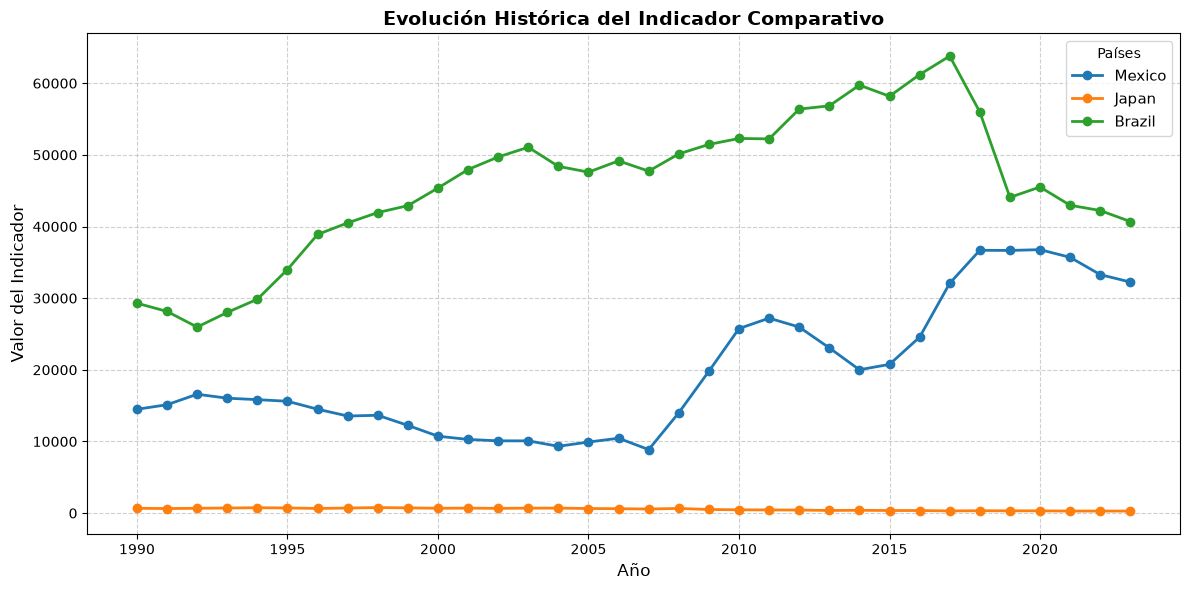

In [214]:
# Pregunta 8
# Tu codigo aqui
paises_grafica = ['Mexico', 'Japan', 'Brazil']

plt.figure(figsize=(12, 6))

for pais in paises_grafica:
    df_temp = df_paises[df_paises['entity'] == pais]
    df_temp = df_temp.sort_values(by='year')
    plt.plot(df_temp['year'], df_temp['valor'], marker='o', linestyle='-', linewidth=2, label=pais)

plt.title('Evolución Histórica del Indicador Comparativo', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Valor del Indicador', fontsize=12)

plt.legend(title='Países', fontsize=11)

plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

plt.show()


**Interpretación:**

Brazil muestra que disminuyeron los homicidios significativamente, mostrando una tendencia hacia la baja a comparación de México que muestra que va en aumento y Japón está tan por debajo de estos dos países que no se alcanza a ver como varían los datos

### Pregunta 9 — Visualización integradora

Crea dos gráficas de barras (horizontales o verticales) con el Top 10 de países según tu indicador en la primera consulta el año de tu nacimiento, y en la segunda el año 2023, ordenados de mayor a menor.  Qué movimientos hubo en ambas gráficas?
Agrega título y etiquetas de ejes.

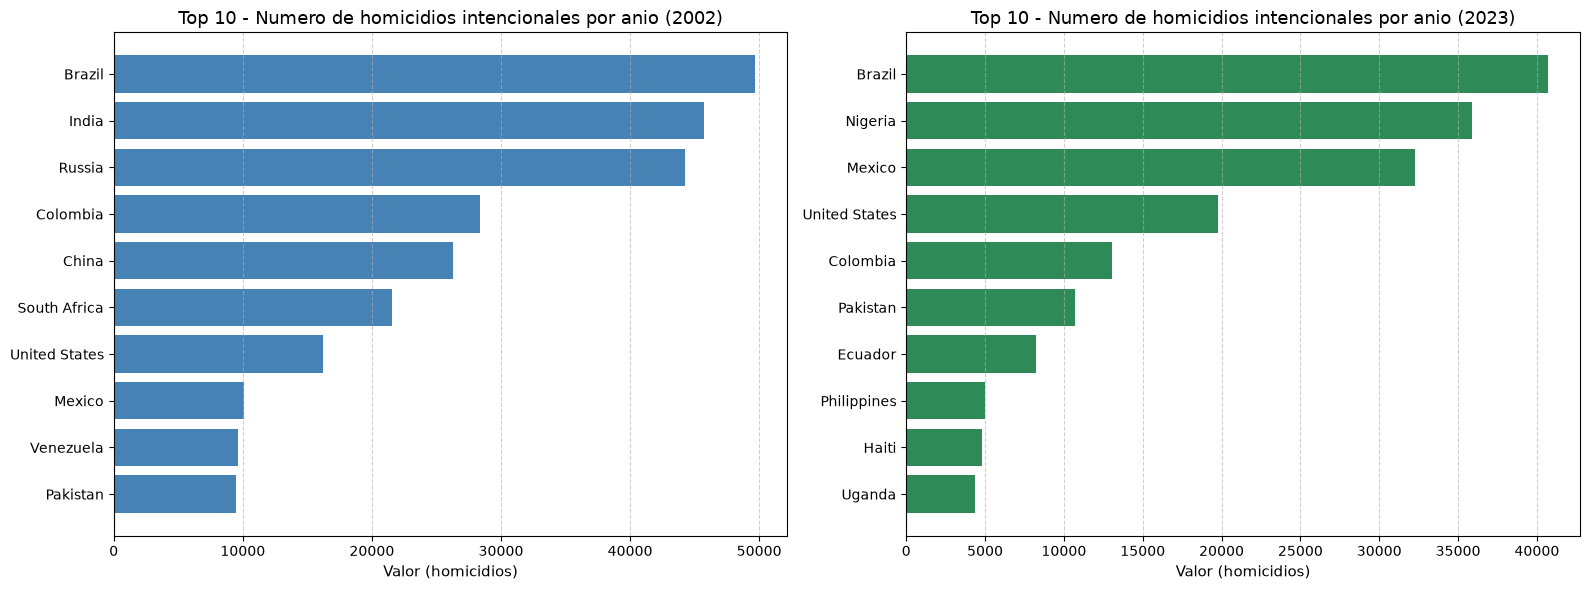

In [215]:
import matplotlib.pyplot as plt

# 1. Preparar los datos para ambos años
anio_nacimiento = 2002
anio_reciente = 2023

# Top 10 del año de nacimiento (2002)
top_nacimiento = (
    df_paises[df_paises['year'] == anio_nacimiento]
    .sort_values('valor', ascending=False)
    .head(10)
)

# Top 10 del año 2023
top_2023 = (
    df_paises[df_paises['year'] == anio_reciente]
    .sort_values('valor', ascending=False)
    .head(10)
)

# 2. Crear una figura con dos subgráficas lado a lado (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Gráfica 1: Año de Nacimiento (2002) ---
ax1.barh(top_nacimiento['entity'], top_nacimiento['valor'], color='steelblue')
ax1.set_xlabel(f"Valor ({config['unidad']})", fontsize=11)
ax1.set_title(f"Top 10 - {config['descripcion']} ({anio_nacimiento})", fontsize=13)
ax1.invert_yaxis()  # El valor más alto queda arriba
ax1.grid(axis='x', linestyle='--', alpha=0.6)

# --- Gráfica 2: Año Reciente (2023) ---
ax2.barh(top_2023['entity'], top_2023['valor'], color='seagreen')
ax2.set_xlabel(f"Valor ({config['unidad']})", fontsize=11)
ax2.set_title(f"Top 10 - {config['descripcion']} ({anio_reciente})", fontsize=13)
ax2.invert_yaxis()  
ax2.grid(axis='x', linestyle='--', alpha=0.6)

# Ajustar los márgenes para que nada se superponga
plt.tight_layout()
plt.show()

**Interpretación:**

Brazil se mantuvo al tope después de 20 años pero es preocupante lo mucho que subió México y Nigeria, que esto demuestra que en los últimos 20 años, estos países han estado teniendo problemas de seguridad

## 5. Conclusión general

En 5 - 10 líneas, resume qué aprendiste sobre el dataset que te tocó trabajar: ¿qué
patrones encontraste?, ¿qué limitaciones tiene la información (por ejemplo, valores
absolutos sin normalizar por población, datos faltantes, etc.)?, ¿qué harías distinto si
tuvieras más tiempo?

Encontré que en LATAM y África suele haber mayor tasa de homicidios intencionales, demostrando que son zonas más peligrosas para vivir y también la situación social de estas regiones es problemática. Faltarían datos sobre la cantidad de habitantes por país para comparar la relacion entre la cantidad de homicidios intencionales por cada habitante para poder aproximar el porcentaje de población para estimar los datos en proporción a ellos, porque es muy diferente comparar a México y Japón cuando hasta su población es mucho más pequeña, nos da un dato pero no en perspectiva , porque puede que sean pocos homicidios a comparación de otro país pero en compraración de su población puede que sean demasiados

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envia una copia del notebook por teams.
